In [1]:
import pandas as pd
import sqlite3

In [2]:
custdf = pd.read_csv("store_customers.csv")

In [3]:
custdf.head()

,customer_id,name,city,signup_year
0,1,Ana Lopez,Venice,2021
1,2,Ben Kim,Culver City,2023
2,3,Chloe Nguyen,Santa Monica,2021
3,4,Dev Patel,Los Angeles,2026
4,5,Elena Garcia,Culver City,2022


In [4]:
custdf.shape

(40, 4)

In [5]:
ordersdf = pd.read_csv("store_orders.csv")

In [6]:
ordersdf.head()

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [7]:
ordersdf.shape

(200, 6)

In [8]:
con = sqlite3.connect("store.db")
custdf.to_sql("customers", con, if_exists="replace", index=False)

40

In [9]:
ordersdf.to_sql("orders", con, if_exists="replace", index=False)

200

In [10]:
pd.read_sql("SELECT name FROM sqlite_master", con)

,name
0,*
1,ix_*_index
2,customers
3,orders


In [11]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [12]:
pd.read_sql("SELECT amount FROM orders WHERE amount > 100 ORDER BY amount DESC", con)

,amount
0,499.00
1,295.36
2,293.79
3,293.35
4,287.83
...,...
79,110.31
80,108.47
81,107.20
82,103.77


In [13]:
pd.read_sql("SELECT category, COUNT(*) AS n, AVG(amount) AS avg_amount FROM orders GROUP BY category ORDER BY avg_amount DESC", con)

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


Above we can see that "electronics" is the most lucrative category in our "orders" dataset, as it has the greatest total profit (~190.57).

In [14]:
pd.read_sql(
    "SELECT c.city, o.amount FROM customers c JOIN orders o ON c.customer_id = o.customer_id", con)

,city,amount
0,Venice,40.90
1,Culver City,13.47
2,Culver City,19.72
3,Culver City,22.06
4,Culver City,42.37
...,...,...
190,Los Angeles,159.23
191,Los Angeles,184.65
192,Los Angeles,216.03
193,Santa Monica,22.64


In [15]:
pd.read_sql(
    "SELECT c.city, SUM(o.amount) FROM customers c JOIN orders o ON c.customer_id = o.customer_id GROUP BY c.city", con)

,city,SUM(o.amount)
0,Culver City,5316.88
1,Inglewood,2718.25
2,Los Angeles,5862.99
3,Santa Monica,4017.93
4,Torrance,1037.25
5,Venice,462.36


The total number of rows in the "orders" dataset is 200, but the rows included in the JOIN is only 195. This is because an INNER JOIN was used, meaning that the query only returned rows that matched the requirements for both CSVs. That is, there were five rows in the "orders" CSV that possessed no "customer_id" values. We used "customer_id" from the "customers" CSV as the basis for the INNER JOIN, so the JOIN included only the 195 rows from the "orders" CSV that contained "customer_id" values that synced up to those in the "customers" CSV. The leftover 5 rows were orders that did not come from registered customers.

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
citiesdf = pd.read_sql(
    "SELECT c.city, SUM(o.amount) FROM customers c JOIN orders o ON c.customer_id = o.customer_id GROUP BY c.city", con)

<function matplotlib.pyplot.show(close=None, block=None)>

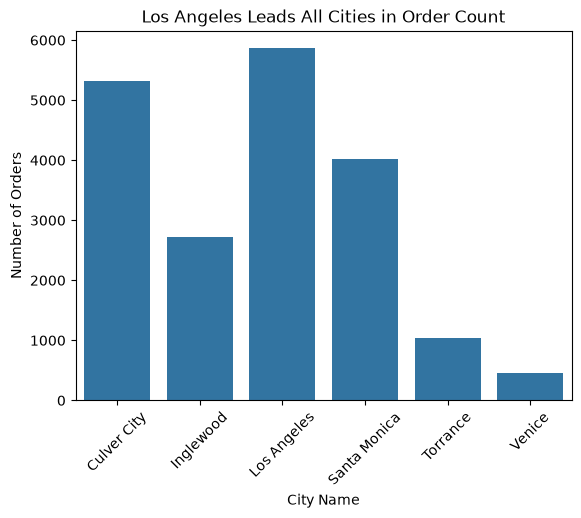

In [17]:
sns.barplot(data=citiesdf, x="city", y="SUM(o.amount)")
plt.title("Los Angeles Leads All Cities in Order Count")
plt.xlabel("City Name")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show

After examining the data, it seems worthwhile to assess how much profit each item earns. If we determine the items that are associated with the most expensive orders, the company can decide to incorporate that into its business decisions.

In [18]:
pd.read_sql(
    "SELECT product, COUNT(*) AS n, AVG(amount) AS avg_amount FROM orders GROUP BY product ORDER BY avg_amount DESC", con)

,product,n,avg_amount
0,headset,23,213.143478
1,monitor,17,186.748824
2,dock,20,167.857000
3,shelf,19,159.497368
4,chair,17,152.348824
5,desk,10,110.719000
6,planner,13,31.725385
7,pens,20,29.889000
8,paper,18,29.252778
9,tea,14,15.500714


In [19]:
productsdf = pd.read_sql(
    "SELECT product, COUNT(*) AS n, AVG(amount) AS avg_amount FROM orders GROUP BY product ORDER BY avg_amount DESC", con)

<function matplotlib.pyplot.show(close=None, block=None)>

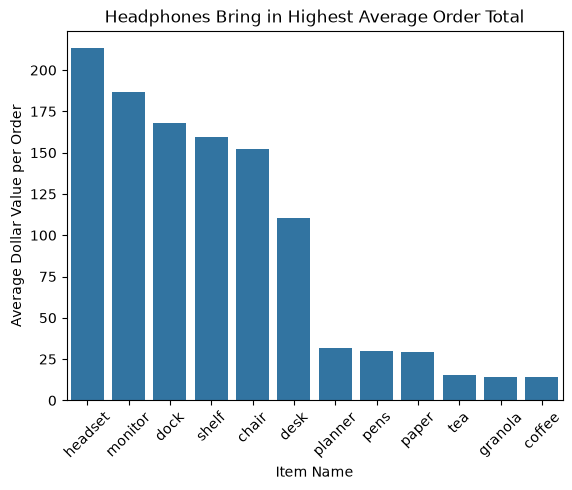

In [20]:
sns.barplot(data=productsdf, x="product", y="avg_amount")
plt.title("Headphones Bring in Highest Average Order Total")
plt.xlabel("Item Name")
plt.ylabel("Average Dollar Value per Order")
plt.xticks(rotation=45)
plt.show

From the above chart, we can see that while there are several items that are bought in expensive quantities, headsets constituted the most expensive orders. There also is a very visible drop-off between desks and planners, indicating that stationery and snacks do not earn the company nearly as much revenue as furniture and related items do.

In regards to sharing results publicly, precautions must be taken to prevent customers' private information being compromised. Especially of note is the list of customers' names because releasing this information without the customers' consent violates their privacy. While the "customer_id" values and "city" information are less directly revealing, it would nonetheless be prudent to keep the "customer_id" numbers private and only publish information about the "city" values in the aggregate, to avoid information being traced back to individual customers.

Github Repo Url: https://github.com/journeyrahman/cs82a-portfolio